# Building an optimal portfolio system

1) Forecast (currently vry simple OLS)
2) Risk model (factor model)
3) Cost model (currently with only spread)
4) Optimization framework (with scaling and factor sparsity for numerical stability)

### Issues
- Covariance matrix currently still in standardized returns. Need to change units by adding the garch modeled term.

## Gathering Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_50_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11,
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)).alias("spread_return"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["mid", "spread_return"]).last()
    )
    .rename({"mid":"entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,40,00), pl.time(15,49,59)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
    )
    .rename({"mid":"recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
    )
    .collect(engine="streaming")
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns(
        (
            pl.col("sign") * pl.col("dollar_imbalance")
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            (pl.col("paired_dollars") / pl.col("ADV"))
        ).alias("auction_dollar_volume_ratio"),
        (
            pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
    .with_columns(
        (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("close_return_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (pl.col("auction_dollar_volume_ratio") - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
        (
            ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))) 
             / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("norm_rank_net_imb")).alias("norm_rank_net_x_auction"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("recent_return_xm")).alias("auction_x_recent_xm")
    )
)

test_data = data.filter(pl.col("date").is_between(pl.date(2026,2,1), pl.date(2026,6,11), closed="both"))
test_data

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,auction_dollar_volume_ratio,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm,norm_rank_net_x_auction,auction_x_recent_xm
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-02-02,"""AAPL""","""A""",4777020,269.86,269.885,0.000037,270.01,3.0891e9,0.00234,2.3978e8,1.2891e9,-1,-2.3978e8,0.417321,-0.186001,0.000463,0.000242,0.002559,0.058242,-0.333333,-0.000853,-0.019414,0.000149
2026-02-02,"""ABNB""","""B""",337164,131.4,131.4,0.000152,131.31,1.0491e8,-0.000228,656211.6,4.4303e7,1,656211.6,0.422288,0.014812,-0.000685,-0.000906,-0.000009,0.063209,0.5,-0.000004,0.031605,-5.5471e-7
2026-02-02,"""ADBE""","""B""",239440,292.72,292.705,0.000307,293.38,3.4677e8,0.00065,2.7188e6,7.0089e7,1,2.7188e6,0.202119,0.038791,0.002306,0.002085,0.000869,-0.15696,0.583333,0.000507,-0.09156,-0.000136
2026-02-02,"""ADI""","""B""",466700,315.72,315.62,0.00057,316.86,2.2397e8,-0.003662,3.0344e7,1.47346524e8,1,3.0344e7,0.657886,0.20594,0.003929,0.003708,-0.003442,0.298808,0.958333,-0.003299,0.286358,-0.001029
2026-02-02,"""AMAT""","""B""",543712,326.07,326.075,0.000521,328.4,4.8717e8,-0.003728,3.1992e7,1.7729e8,1,3.1992e7,0.363912,0.18045,0.00713,0.006909,-0.003509,0.004833,0.875,-0.00307,0.004229,-0.000017
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""SMCI""","""A""",4354983,29.88,29.895,0.000335,29.27,3.8004e8,-0.008293,3.7688e6,1.3013e8,-1,-3.7688e6,0.342406,-0.028962,-0.020907,-0.018335,-0.006376,-0.053774,0.083333,-0.000531,-0.004481,0.000343
2026-06-10,"""TMUS""","""B""",452753,184.92,184.93,0.000433,185.55,1.8681e8,0.000135,9.1352e6,8.3723e7,1,9.1352e6,0.448171,0.109112,0.003353,0.005924,0.002053,0.051991,0.666667,0.001369,0.034661,0.000107
2026-06-10,"""TSLA""","""B""",1802045,382.16,382.18,0.000052,381.59,3.3318e9,-0.001033,2.5933e7,6.8867e8,1,2.5933e7,0.206695,0.037657,-0.001544,0.001028,0.000885,-0.189485,0.458333,0.000406,-0.086847,-0.000168


In [4]:
[s for s in ACTIVE_SET if s not in test_data.select("symbol").unique().to_numpy()]

['CRWV']

## Daily MVO Optimizer

In [5]:
import cvxpy as cp
import scipy

class ForecastModel:
    def __init__(self, universe, model, features):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.model = model
        self.features = features

    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        alpha = np.zeros(len(self.universe))
        preds = self.model.predict(day_df[self.features].to_numpy()).ravel()  # scaled inside pipeline
        for symbol, p in zip(day_df["symbol"], preds):
            alpha[self.sym_idx_map[symbol]] = p
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}
    
    def get_cost(self, day_df: pl.DataFrame, commission: float) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread, comm_rate in zip(day_df["symbol"], day_df["spread_return"], commission / day_df['entry_price']):
            cost[self.sym_idx_map[symbol]] = (spread * 0.5) + (2 * comm_rate)
        return cost

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        self.scale = None
        
    def set_problem(self, Sigma_r, Sigma_f, Loadings, eps_diag, lam, gam, vol_cap, scale = None):
        # -- Variables --
        self.x     = cp.Variable(self.N)
        self.alpha = cp.Parameter(self.N)
        self.cost  = cp.Parameter(self.N, nonneg=True)
        self.gamma = gam
        self.Sigma_r = cp.Constant(Sigma_r)
        self.L = cp.Constant(Loadings)
        self.eps_diag = eps_diag
        self.scale = float(vol_cap if scale is None else scale)
        self.D = np.diag(eps_diag)
        self.lamdba = cp.Constant(lam)
        
        # -- Objective --
        self.objective = cp.Maximize(
            self.alpha @ self.x
            - (self.lamdba * self.scale / 2) * ( cp.quad_form(self.L @ self.x, Sigma_f) + cp.quad_form(self.x, self.D) )
            - (self.cost / 2) @ cp.abs(self.x)
            # - (self.scale / 2) * cp.quad_form(self.x, np.diag(self.gamma))
        )

        # -- Constraints --
        Sigma_f_sqrt = scipy.linalg.sqrtm(Sigma_f).real
        D_sqrt  = np.sqrt(self.eps_diag)
        quad_risk = cp.norm(cp.hstack([Sigma_f_sqrt @ self.L @ self.x, cp.multiply(D_sqrt, self.x)]), 2)   # = √(xᵀΣx) but numerically sparse with factors
        self.constraints = [
            # cp.sum(self.x) == 0,                       # dollar neutrality
            quad_risk <= vol_cap / self.scale,           # Expected volatility √(xᵀΣx) ≤ target daily dollar volatility, with scale factor
        ]
        # Three factor-neutrality
        self.constraints += [self.x @ Loadings[i,:] == 0 for i in range(0,2)]
        self.problem = cp.Problem(self.objective, self.constraints)

    def solve(self, alpha, cost) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value  = cost
        self.problem.solve(solver=cp.CLARABEL)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        # -- Dollar denominated optimal portfolio
        return self.x.value * self.scale

## Parallelized Daily Optimization

Each trading day is an independent QP (the book is flat at every close), so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

### Loading Forecast and Risk Models

In [6]:
import joblib

# Load the model back into memory
loaded_model = joblib.load("../forecast/forecast_pipe.joblib")
features = [
        "norm_rank_net_imb", 
        "recent_return_xm",
        "auction_dollar_volume_ratio_xm", 
        "norm_rank_net_x_recent_xm",
        "norm_rank_net_x_auction",
    ]
# --- Now using returns units versions with sample volatilities over training window---
L        = np.load("../covariance/loadings_return.npy")          # was loadings.npy
EPS_DIAG = np.load("../covariance/idiosyncratic_diag_return.npy") # was idiosyncratic_diag_vec.npy
SIGMA_F  = np.load("../covariance/factor_cov_matrix.npy")         # unchanged
SIGMA_R  = np.load("../covariance/cov_matrix_return.npy")         # was cov_matrix.npy
GAMMA_DIAG  = np.load("../impact/impact_gamma_vec.npy")


f_model = ForecastModel(ACTIVE_SET, model=loaded_model, features=features)
c_model = CostModel(ACTIVE_SET)

### Hyperparams and Backtesting

In [7]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed
import warnings


N_JOBS = max(1, os.cpu_count() - 2)
COMMISSION_PER_SHARE = 0.0035
LAMBDA = 1e-5                            # Risk aversion per dollar, ~OOM of 1 / (intended capital).
DAILY_DOLLAR_VOL_CAP = 5e4

def _solve_chunk(symbols, Sigma_r, Sigma_f, Loadings, eps_diag, lam, gam, vol_cap, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    warnings.filterwarnings("ignore", message="Solution may be inaccurate")
    opt = Optimizer(symbols)
    opt.set_problem(Sigma_r=Sigma_r, Sigma_f=Sigma_f, Loadings=Loadings, 
                    eps_diag=eps_diag, lam=lam, gam=gam, vol_cap=vol_cap)        # compile once per worker, not per day
    return [(date, opt.solve(alpha, cost)) for date, alpha, cost in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = test_data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day, COMMISSION_PER_SHARE))
    for d in all_dates
    for day in [test_data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, LAMBDA, GAMMA_DIAG, DAILY_DOLLAR_VOL_CAP, chunk) for chunk in chunks
)

weights = {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

solved 90 days across 12 workers


### Plotting / Accounting

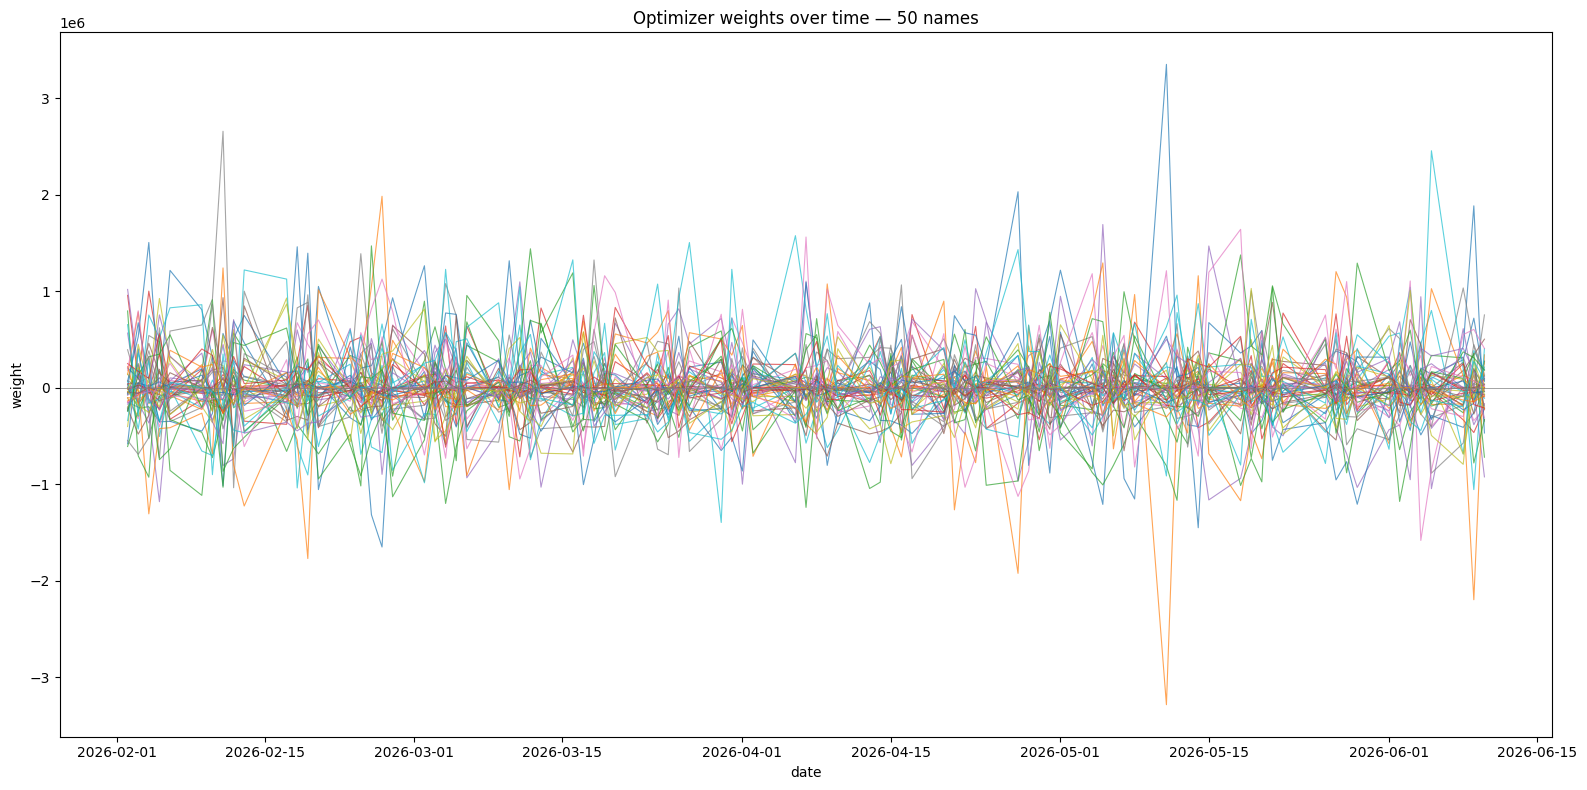

In [8]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())

held = sorted({s for d in dates for s, wv in weights[d].items()})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time — {len(held)} names")
fig.tight_layout()
plt.show()

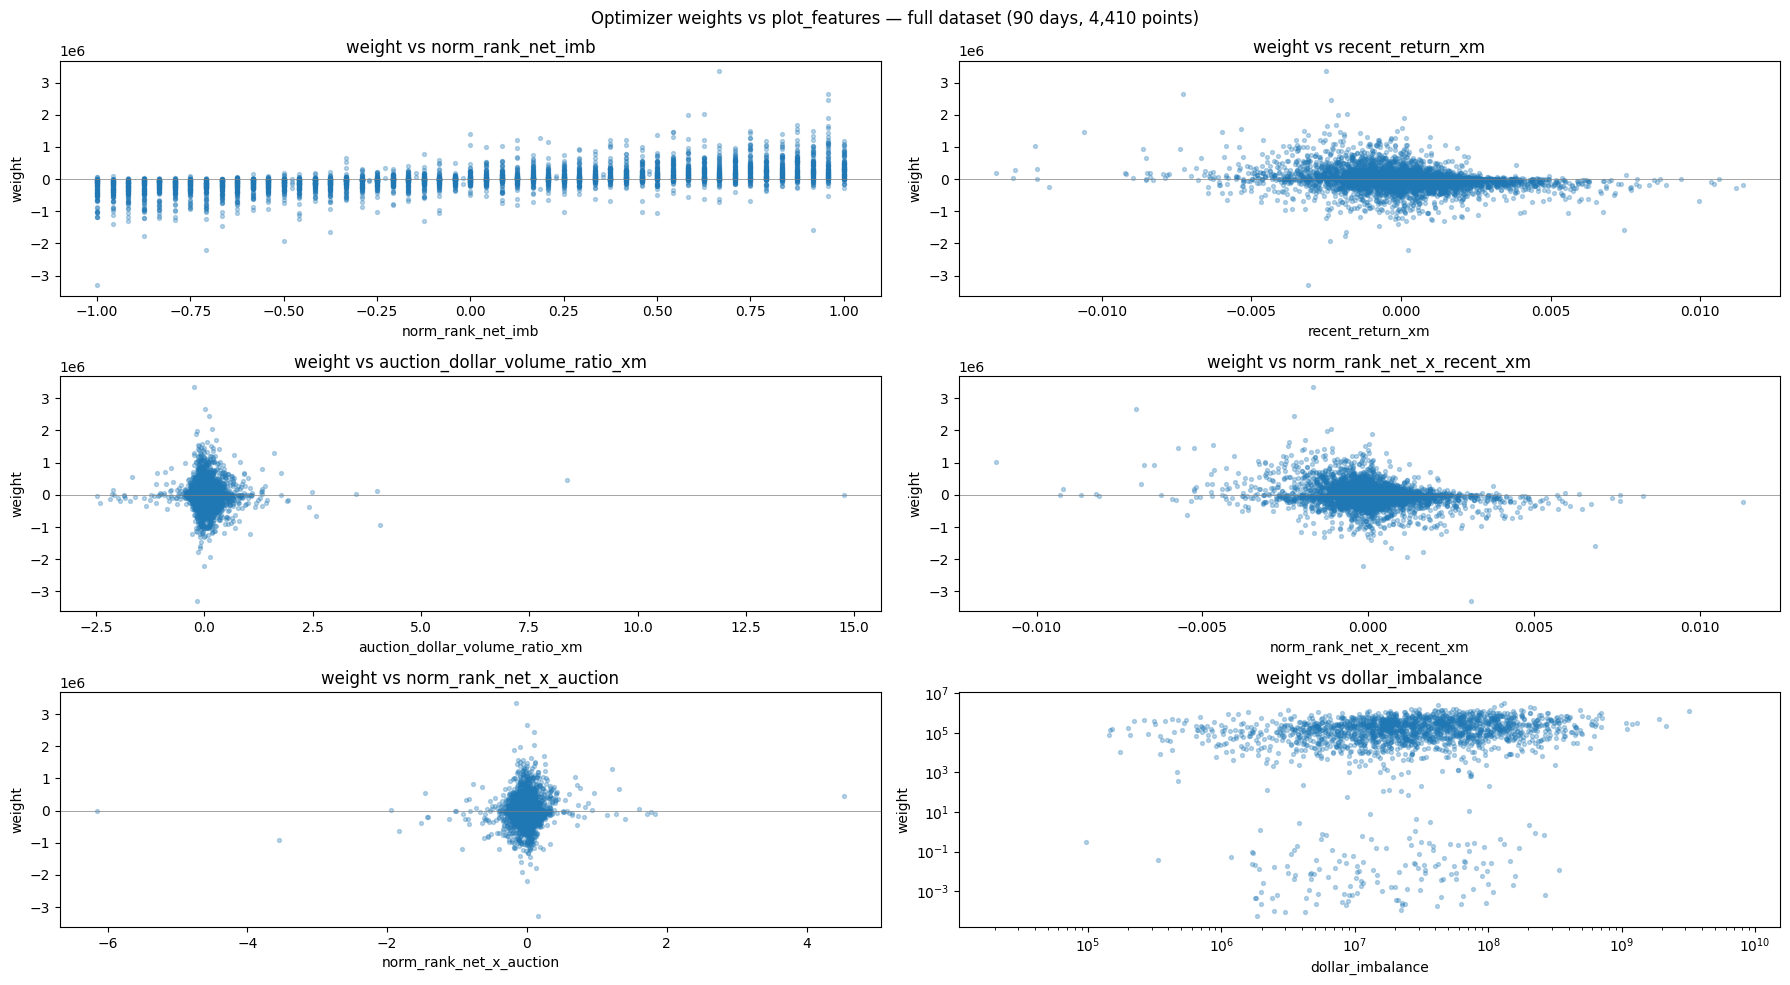

In [9]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = test_data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear
plot_features = features + ["dollar_imbalance"]

fig, axes = plt.subplots(3, 2, figsize=(18, 10))
for ax, feat in zip(axes.flat, plot_features):
    x = plot_df[feat].to_numpy()
    ax.scatter(x, weights_arr, alpha=0.3, s=8)
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("weight")
    ax.set_title(f"weight vs {feat}")

fig.suptitle(f"Optimizer weights vs plot_features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

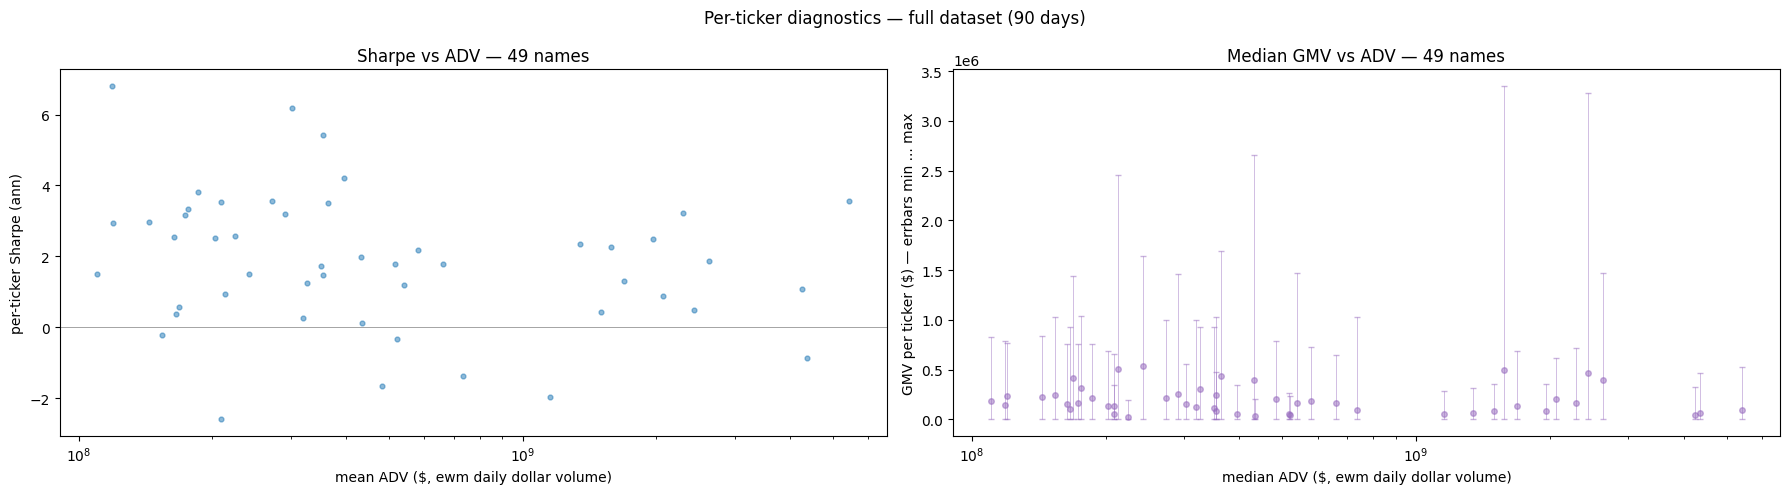

In [10]:
# Per-ticker scatters over the FULL dataset: Sharpe vs ADV, and mean GMV vs ADV.
# Rebuilds per-name daily net PnL with the SAME cost model as the PnL cell below,
# then collapses to one point per ticker:
#   - Sharpe_i  = mean_t(net_pnl_i,t) / std_t(net_pnl_i,t) * sqrt(252)   (zero-position days included)
#   - GMV_i,t   = |$pos_i,t|  -> mean per ticker, with bars spanning its min..max
#   - ADV_i     = mean of the day's ewm daily dollar volume for that name
ANN = 252

pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

name_daily = (
    test_data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate")
    )
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")
         - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
        pl.col("dollar_pos").abs().alias("gmv_name"),
    )
)

per_name = (
    name_daily
    .group_by("symbol")
    .agg(
        (pl.col("net_pnl_name").mean() / pl.col("net_pnl_name").std(ddof=1) * np.sqrt(ANN)).alias("sharpe"),
        pl.col("ADV").mean().alias("adv_mean"),
        pl.col("gmv_name").mean().alias("gmv_mean"),
        pl.col("gmv_name").median().alias("gmv_median"),
        pl.col("gmv_name").min().alias("gmv_min"),
        pl.col("gmv_name").max().alias("gmv_max"),
        pl.len().alias("n_days"),
    )
    .filter((pl.col("n_days") > 1) & pl.col("sharpe").is_finite())
    .sort("adv_mean")
)

adv      = per_name["adv_mean"].to_numpy()
sharpe_n = per_name["sharpe"].to_numpy()
gmv_median = per_name["gmv_median"].to_numpy()
gmv_lo   = gmv_median - per_name["gmv_min"].to_numpy()   # bar down to min (>= 0)
gmv_hi   = per_name["gmv_max"].to_numpy() - gmv_median   # bar up to max   (>= 0)

fig, (axS, axG) = plt.subplots(1, 2, figsize=(18, 5))

axS.scatter(adv, sharpe_n, alpha=0.5, s=12)
axS.axhline(0, color="grey", lw=0.5)
axS.set_xscale("log")
axS.set_xlabel("mean ADV ($, ewm daily dollar volume)")
axS.set_ylabel("per-ticker Sharpe (ann)")
axS.set_title(f"Sharpe vs ADV — {len(per_name)} names")

axG.errorbar(adv, gmv_median, yerr=[gmv_lo, gmv_hi], fmt="o", ms=4, alpha=0.5,
             elinewidth=0.6, capsize=2, color="tab:purple")
axG.set_xscale("log")
# axG.set_yscale("log")
axG.set_xlabel("median ADV ($, ewm daily dollar volume)")
axG.set_ylabel("GMV per ticker ($) — errbars min ... max")
axG.set_title(f"Median GMV vs ADV — {len(per_name)} names")

fig.suptitle(f"Per-ticker diagnostics — full dataset ({len(weights)} days)")
fig.tight_layout()
plt.show()

Days traded:        90
Mean GMV:           $10,962,006
Median GMV:         $10,817,676
Max GMV:            $16,978,421  (1.5x mean GMV)
Gross PnL:          $619,814
Total cost:         $181,353
Total net PnL:      $438,461
Max drawdown:       -0.3%
Sharpe (ann):       8.80
Daily hit rate:     82.2%


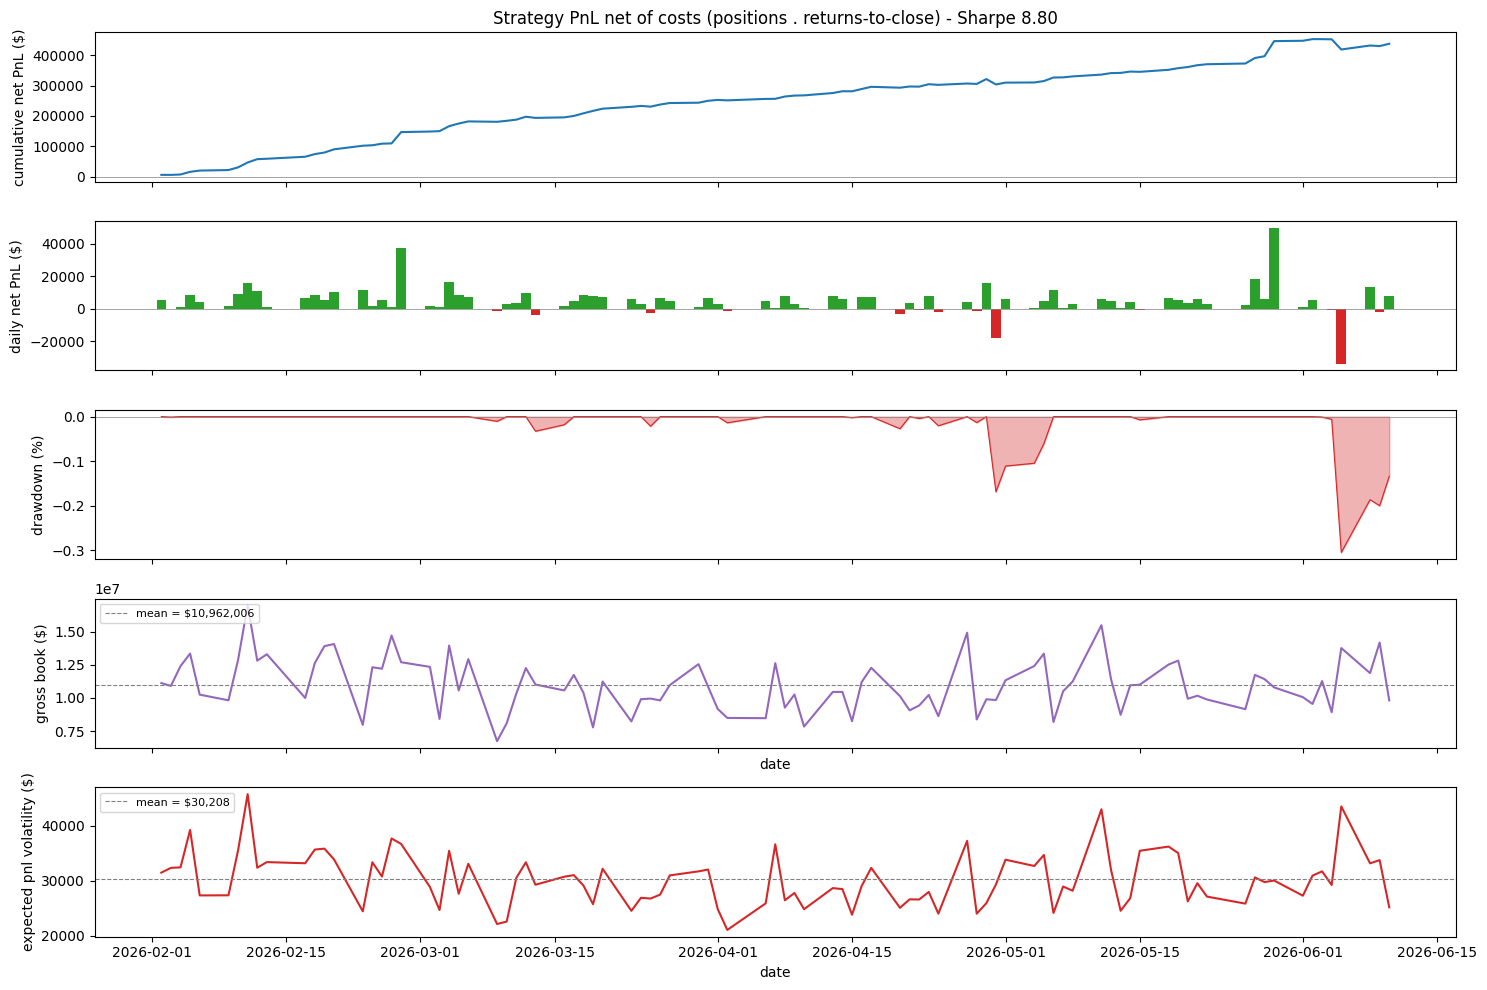

In [ ]:
# ===== Strategy PnL: dollar positions . returns-to-close, net of costs =====
# `weights` is the optimizer's ABSOLUTE-DOLLAR book per day: {date: {symbol: $ position}}.
# Daily gross PnL = sum_i (dollar position_i) * (return from entry to the closing auction_i).
# Costs charged as a dot product  |$pos| . cost_rate:
#   - spread:     HALF the quoted spread, ENTRY only (the auction exit has no spread).
#   - commission: $0.0035/share on BOTH legs; spread_return already bundles 0.0035/price (one leg).
ANN = 252


# Flatten {date: {symbol: $pos}} -> long, then join the day's prices/spread from `data`.
pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

pnl_daily = (
    test_data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")).alias("gross_pnl"),                       # $pos . return
        (COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"),                        # per-leg commission, as a return
    )
    # spread_return is the pure quoted spread (ask-bid)/mid. Charge half the spread (cross ONCE
    # on entry; the auction exit has no spread) + commission on BOTH legs.
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate"),
    )
    .with_columns(
        (pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("cost"),                         # dot product: |$pos| . cost_rate
        (pl.col("gross_pnl") - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
    )
    .group_by("date")
    .agg(
        pl.col("net_pnl_name").sum().alias("net_pnl"),
        pl.col("gross_pnl").sum().alias("gross_pnl"),
        pl.col("cost").sum().alias("cost"),
        pl.col("dollar_pos").abs().sum().alias("GMV"),         # gross book deployed that day
    )
    .sort("date")
    .with_columns(pl.col("net_pnl").cum_sum().alias("cum_pnl"))
)

# ----- stats -----
pnl  = pnl_daily["net_pnl"].to_numpy()
cum_pnl  = pnl_daily["cum_pnl"].to_numpy()
mean_gmv = pnl_daily["GMV"].mean()
median_gmv = pnl_daily["GMV"].median()
rolling_mean_gmv = pnl_daily["GMV"].ewm_mean(alpha=0.06, adjust=True)   
max_gmv = pnl_daily["GMV"].max()
# -- factor decomposition for expected risk --
# √ (xᵀ @ Σ @ x) = √ [ (L @ x)ᵀ @ Σ_𝘍 @ (L @ x) + (xᵀ @ D @ x) ]
exp_vol = [
    np.sqrt(
        (L @ np.array([weights[d][s] for s in ACTIVE_SET]))
        @ SIGMA_F
        @ (L @ np.array([weights[d][s] for s in ACTIVE_SET]))
        + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)
    ) for d in weights
]

# Drawdown of the cumulative net-PnL curve (underwater, in $): current - running peak (<= 0).
peak      = np.maximum.accumulate(cum_pnl)
drawdown  = 100 * (cum_pnl - peak) / (peak + rolling_mean_gmv)
max_dd    = drawdown.min()                          # deepest trough ($, <= 0)

sharpe  = pnl.mean() / pnl.std(ddof=1) * np.sqrt(ANN)

print(f"Days traded:        {len(pnl)}")
print(f"Mean GMV:           ${mean_gmv:,.0f}")
print(f"Median GMV:         ${median_gmv:,.0f}")
print(f"Max GMV:            ${max_gmv:,.0f}  ({max_gmv / mean_gmv:,.1f}x mean GMV)")
print(f"Gross PnL:          ${pnl_daily['gross_pnl'].sum():,.0f}")
print(f"Total cost:         ${pnl_daily['cost'].sum():,.0f}")
print(f"Total net PnL:      ${pnl.sum():,.0f}")
print(f"Max drawdown:       {max_dd:,.1f}%")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Daily hit rate:     {(pnl > 0).mean():.1%}")

# ----- plots: cumulative PnL, daily PnL, drawdown, gross book -----
dts   = pnl_daily["date"].to_list()
gmv = pnl_daily["GMV"].to_numpy()
fig, (ax_pnl, ax_bar, ax_dd, ax_gmv, ax_vol) = plt.subplots(5, 1, figsize=(15, 10), sharex=True, height_ratios=[1, 1, 1, 1, 1])

ax_pnl.plot(dts, cum_pnl, color="tab:blue")
ax_pnl.axhline(0, color="grey", lw=0.5)
ax_pnl.set_ylabel("cumulative net PnL ($)")
ax_pnl.set_title(f"Strategy PnL net of costs (positions . returns-to-close) - Sharpe {sharpe:.2f}")

ax_bar.bar(dts, pnl, color=np.where(pnl >= 0, "tab:green", "tab:red"), width=1.0)
ax_bar.axhline(0, color="grey", lw=0.5)
ax_bar.set_ylabel("daily net PnL ($)")

# Underwater curve: distance below the running high-water mark of cumulative PnL.
ax_dd.fill_between(dts, drawdown, 0.0, color="tab:red", alpha=0.35)
ax_dd.plot(dts, drawdown, color="tab:red", lw=0.8)
ax_dd.axhline(0, color="grey", lw=0.5)
dd_idx = int(np.argmin(drawdown))
# ax_dd.annotate(f"max DD {max_dd*100:,.1f}%", xy=(dts[dd_idx], max_dd),
#                xytext=(5, 8), textcoords="offset points", fontsize=8, color="tab:red")
ax_dd.set_ylabel("drawdown (%)")

ax_gmv.plot(dts, gmv, color="tab:purple")
ax_gmv.axhline(mean_gmv, color="grey", lw=0.8, ls="--", label=f"mean = ${mean_gmv:,.0f}")
ax_gmv.set_ylabel("gross book ($)")
ax_gmv.set_xlabel("date")
ax_gmv.legend(loc="upper left", fontsize=8)

ax_vol.plot(dts, exp_vol, color="tab:red")
ax_vol.axhline(np.nanmean(exp_vol), color="grey", lw=0.8, ls="--", label=f"mean = ${np.nanmean(exp_vol):,.0f}")
ax_vol.set_ylabel("expected pnl volatility ($)")
ax_vol.set_xlabel("date")
ax_vol.legend(loc="upper left", fontsize=8)
# ax_vol.ticklabel_format(style='plain', axis='y', useOffset=False)


fig.tight_layout()
plt.show()

# pnl_daily

#### Some diagnostics

In [12]:
ANN = 252
alpha_by_day = {d: a for d, a, _ in day_records}      # dense alpha, ACTIVE_SET order
cost_by_day = {d: c for d, _, c in day_records}

exante = []
for d in sorted(weights):
    x = np.array([weights[d][s] for s in ACTIVE_SET])            # $ positions, same order
    a = alpha_by_day[d]                                          # expected returns
    exp_pnl = a @ x - cost_by_day[d] @ np.abs(x)                 # net expected daily $ PnL
    exp_var = (L @ x) @ SIGMA_F @ (L @ x) + np.sum(EPS_DIAG * x**2)   # matches optimizer's risk term
    exante.append(exp_pnl / np.sqrt(exp_var) if exp_var > 0 else np.nan)

exante = np.array(exante)
print(f"Mean expected $vol:   {np.nanmean([np.sqrt((L@np.array([weights[d][s] for s in ACTIVE_SET]))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")
print(f"Max expected $vol:   {np.nanmax([np.sqrt((L@np.array([weights[d][s] for s in ACTIVE_SET]))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")

Mean expected $vol:   30,208
Max expected $vol:   45,732


In [13]:
from scipy.stats import pearsonr, spearmanr
r, pval = spearmanr(pnl_daily["GMV"], pnl_daily["cum_pnl"])
print(f"Spearman Corr of GMV and PnL: {r:,.5f}")

Spearman Corr of GMV and PnL: -0.16492


### Parameter Sweeps

In [14]:
def _avg_gmv(lam, vol_cap):
    """Solve all days at (lam, vol_cap); return mean daily GMV = mean_t( sum_i |$pos| )."""
    chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
    chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, lam, GAMMA_DIAG, vol_cap, chunk)
        for chunk in chunks
    )
    gmv_by_day = [np.abs(ws).sum() for chunk in chunk_results for _, ws in chunk]
    return float(np.mean(gmv_by_day)), float(np.std(gmv_by_day))

# --- Sweep grids ---
lambda_grid = np.geomspace(1e-9, 1e-7, 100)            # risk aversion per dollar (~ 1/ intended capital)

gmv_vs_lambda = [_avg_gmv(lam, 1e-1 * int(1/lam)) for lam in lambda_grid]

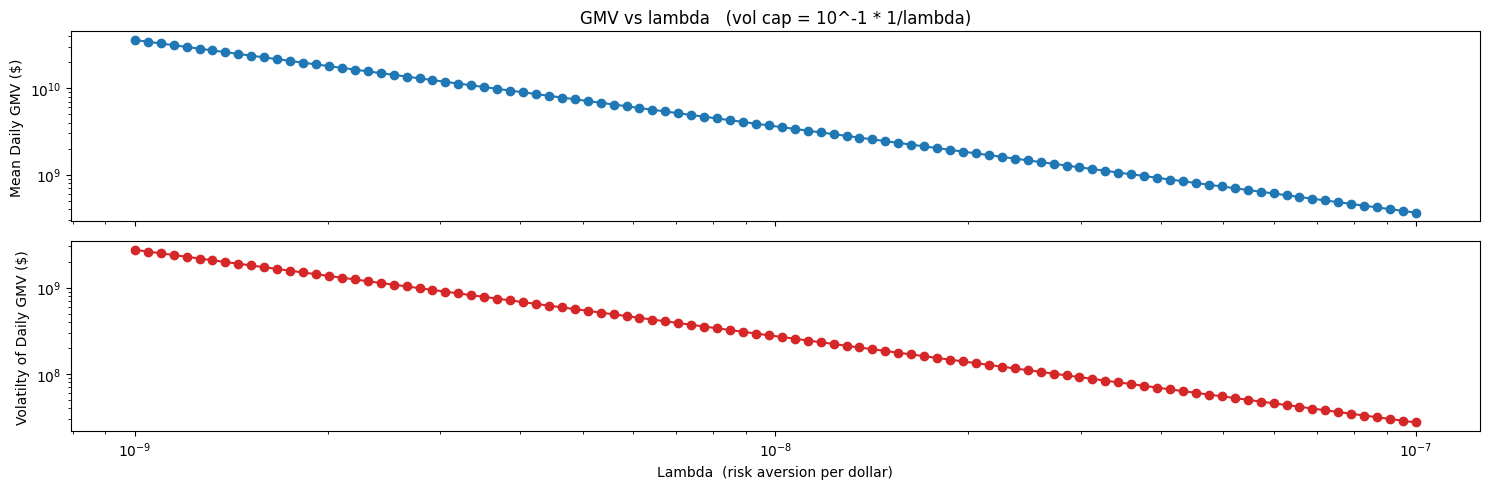

In [15]:
# --- Plots: GMV for each sweep ---
fig, (ax_mean, ax_std) = plt.subplots(2, 1, figsize=(15, 5), sharex=True)

ax_mean.plot(lambda_grid, [mean for (mean, std) in gmv_vs_lambda], marker="o", color="tab:blue")
ax_mean.set_ylabel("Mean Daily GMV ($)")
ax_mean.set_title(f"GMV vs lambda   (vol cap = 10^-1 * 1/lambda)")
ax_mean.set_xscale("log")
ax_mean.set_yscale("log")


ax_std.plot(lambda_grid, [std for (mean, std) in gmv_vs_lambda], marker="o", color="tab:red")
ax_std.set_xlabel("Lambda  (risk aversion per dollar)")
ax_std.set_ylabel("Volatilty of Daily GMV ($)")
ax_std.set_xscale("log")
ax_std.set_yscale("log")

fig.tight_layout()
plt.show()


### Notes
- For impact (toggled off) are  using a simple gamma which is the coef from regressing 1-second returns on signed dollar volume from 15:50:00 - 16:00:00. This is used in the optimizer to have soe kind of quadratic impact cost, but not in the pnl accounting.
- For our covariance we are using a factor model on causal-voltility-standardized returns. This is for better estimation and numerical sparsity. We then use a sample volatility value (with a floor) to get the model back into return units.
- We improved the forecast by using Lasso(alpha=1e-4) with multiple features and interaction terms.

### Next:
- We need a way to account for impact in the accounting? This would give us a better idea of capacity. For now, our estimate of capacity is the lowest GMV for which net pnl is approximately at the cap (check parameter sweeps with impact turned on.)
        - This is the maximum the optimizer is willing to send GMV. Is is not directly dependent on real PNL, since the impact isn't actually accounted for.
- More issues with universe. Some things are in ACTIVE_SET but not UNIVERSE. The universe is fixed adn used throughout. Does not account for renaming.
- What we should be doing is using a rolling/walking universe of the top N **equities** (not etfs, etc.) by ADV/MDV and reconstructing the forecast, covariance, and impact models for each period.

In [16]:
# # ===== Lambda sweep tracking PnL (not just GMV) =====
# # For each lambda, solve all days, then run the SAME cost-netted accounting as the main PnL cell.
# # vol cap is coupled to lambda as 0.0063/lambda, matching the GMV sweep above (so this walks the
# # same lambda<->cap ray). Records the cumulative curve, total net PnL, and annualized Sharpe.
# ANN = 252

# def _solve_all(lam, vol_cap):
#     """Solve every day at (lam, vol_cap); return weights as {date: {symbol: $pos}}."""
#     chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
#     chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
#         delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, lam, GAMMA_DIAG, vol_cap, chunk)
#         for chunk in chunks
#     )
#     return {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}

# def _pnl_daily(weights_d):
#     """Per-day net-of-cost PnL for a weights dict — identical model to the main PnL cell."""
#     pos_long = pl.DataFrame({
#         "date":       [d for d in weights_d for _ in weights_d[d]],
#         "symbol":     [s for d in weights_d for s in weights_d[d]],
#         "dollar_pos": [w for d in weights_d for w in weights_d[d].values()],
#     }).with_columns(pl.col("symbol").cast(pl.Categorical))
#     return (
#         test_data
#         .join(pos_long, on=["date", "symbol"], how="inner")
#         .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
#         .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
#         .with_columns((0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
#                       .clip(lower_bound=0.0).alias("cost_rate"))
#         .with_columns(
#             (pl.col("dollar_pos") * pl.col("ret_to_close")
#              - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
#             pl.col("dollar_pos").abs().alias("gmv_name"),
#         )
#         .group_by("date")
#         .agg(pl.col("net_pnl_name").sum().alias("net_pnl"),
#              pl.col("gmv_name").sum().alias("GMV"))
#         .sort("date")
#         .with_columns(pl.col("net_pnl").cum_sum().alias("cum_pnl"))
#     )

# pnl_lambda_grid = np.geomspace(1e-10, 1e-6, 25)     # risk aversion per dollar (~ 1 / intended capital)
# pnl_sweep = []
# for lam in pnl_lambda_grid:
#     pdl = _pnl_daily(_solve_all(lam, 0.0063 * (1 / lam)))
#     pnl = pdl["net_pnl"].to_numpy()
#     sd  = pnl.std(ddof=1)
#     pnl_sweep.append({
#         "lambda":    lam,
#         "total_pnl": float(pnl.sum()),
#         "sharpe":    float(pnl.mean() / sd * np.sqrt(ANN)) if sd > 0 else np.nan,
#         "mean_gmv":  float(pdl["GMV"].mean()),
#         "dates":     pdl["date"].to_list(),
#         "cum_pnl":   pdl["cum_pnl"].to_numpy(),
#     })
# print(f"swept {len(pnl_sweep)} lambdas from {pnl_lambda_grid[0]:.1e} to {pnl_lambda_grid[-1]:.1e}")

In [17]:
# # --- Plots: PnL across the lambda sweep + best lambda by total net PnL ---
# lams      = np.array([r["lambda"] for r in pnl_sweep])
# total_pnl = np.array([r["total_pnl"] for r in pnl_sweep])
# sharpes   = np.array([r["sharpe"] for r in pnl_sweep])

# best_i   = int(np.nanargmax(total_pnl))
# best_lam = lams[best_i]

# best_i_sharpe   = int(np.nanargmax(sharpes))
# best_lam_sharpe = lams[best_i_sharpe]

# fig, (ax_tot, ax_sh, ax_cum) = plt.subplots(3, 1, figsize=(15, 12))

# ax_tot.plot(lams, total_pnl, marker="o", color="tab:blue")
# ax_tot.axvline(best_lam, color="tab:green", ls="--", lw=1, label=f"best λ = {best_lam:.2e}")
# ax_tot.axhline(0, color="grey", lw=0.5)
# ax_tot.set_xscale("log")
# ax_tot.set_xlabel("Lambda (risk aversion per dollar)")
# ax_tot.set_ylabel("Total net PnL ($)")
# ax_tot.set_title("Total net PnL vs lambda")
# ax_tot.legend(loc="best", fontsize=8)

# ax_sh.plot(lams, sharpes, marker="o", color="tab:purple")
# ax_sh.axvline(best_lam_sharpe, color="tab:green", ls="--", lw=1)
# ax_sh.axhline(0, color="grey", lw=0.5)
# ax_sh.set_xscale("log")
# ax_sh.set_xlabel("Lambda (risk aversion per dollar)")
# ax_sh.set_ylabel("Sharpe (ann)")
# ax_sh.set_title("Sharpe vs lambda")

# cmap = plt.cm.viridis
# for i, r in enumerate(pnl_sweep):
#     ax_cum.plot(r["dates"], r["cum_pnl"], lw=1, alpha=0.6,
#                 color=cmap(i / max(1, len(pnl_sweep) - 1)))
# ax_cum.plot(pnl_sweep[best_i]["dates"], pnl_sweep[best_i]["cum_pnl"],
#             color="tab:green", lw=2.5, label=f"best λ = {best_lam:.2e}")
# ax_cum.axhline(0, color="grey", lw=0.5)
# ax_cum.set_xlabel("date")
# ax_cum.set_ylabel("cumulative net PnL ($)")
# ax_cum.set_title("Cumulative net PnL curves (dark→light = low→high lambda)")
# ax_cum.legend(loc="best", fontsize=8)

# fig.tight_layout()
# plt.show()

# print(f"Best lambda (max total net PnL): {best_lam:.3e}")
# print(f"  total net PnL:  ${pnl_sweep[best_i]['total_pnl']:,.0f}")
# print(f"  Sharpe (ann):   {pnl_sweep[best_i]['sharpe']:.2f}")
# print(f"  mean daily GMV: ${pnl_sweep[best_i]['mean_gmv']:,.0f}")
# # For reference, the lambda with the best Sharpe (may differ from best total PnL):
# best_sh_i = int(np.nanargmax(sharpes))
# print(f"Best lambda by Sharpe:           {lams[best_sh_i]:.3e}  (Sharpe {sharpes[best_sh_i]:.2f}, "
#       f"total net PnL ${pnl_sweep[best_sh_i]['total_pnl']:,.0f})")